# 01 · Análisis exploratorio de imágenes

Este notebook examina el inventario de la fase de comprensión de datos de CRISP-DM. Para regenerar la entrada desde la raíz del repositorio, ejecuta `python -m src.data.inventory` después de instalar los datasets según el README.

Un **archivo** es una imagen del inventario. Un **grupo** reúne variantes o copias de una toma y, en las fotos propias, puede reunir tomas dudosas de una sesión. La cantidad de grupos describe las unidades disponibles para la futura partición. Una misma pieza puede aparecer en distintas tomas sin un identificador conocido.

In [1]:
from pathlib import Path
import sys

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "config.py").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from src import config

if not config.INDEX_CSV.is_file():
    raise FileNotFoundError("Genera el índice con python -m src.data.inventory.")

index = pd.read_csv(config.INDEX_CSV, keep_default_na=False, dtype=str)
labeled = index.loc[
    index["status"].eq("labeled") & index["quality"].isin(config.QUALITY_CLASSES)
].copy()

sources = {"ryandpark": "Kaggle", "agrifreshnet": "AgriFreshNET", "own": "Propias"}

def counts(frame, keys):
    return frame.groupby(keys).agg(
        archivos=("filename", "size"),
        grupos=("group", "nunique"),
    )

by_source = counts(index.assign(source=index["source"].map(sources)), "source")
display(by_source)
display(counts(index, "status"))

,archivos,grupos
source,,
AgriFreshNET,14160,5188
Kaggle,19526,12286
Propias,42,7


,archivos,grupos
status,,
conflicting_quality,68,17
labeled,32579,16581
needs_instance_labels,1075,883
pending_quality,6,1


## Cobertura por producto, calidad y fuente

La primera tabla muestra todos los productos del inventario. Las siguientes usan los registros con etiqueta disponible y sin conflicto conocido. Los grupos se cuentan de nuevo en cada celda. Tres grupos de fotos propias aparecen en más de una clase porque reúnen tomas de una sesión.

In [2]:
coverage = counts(index, "product").join(
    counts(labeled, "product").add_suffix("_con_etiqueta")
).fillna(0).astype(int)
display(coverage)

def class_table(keys):
    return (
        counts(labeled, [*keys, "quality"])
        .unstack(fill_value=0)
        .reindex(columns=pd.MultiIndex.from_product(
            [["archivos", "grupos"], config.QUALITY_CLASSES], names=[None, "quality"]
        ), fill_value=0)
        .sort_index()
    )

display(class_table(["source"]).rename(index=sources))
display(class_table(["product"]))
display(class_table(["source", "product"]).rename(index=sources, level="source"))

,archivos,grupos,archivos_con_etiqueta,grupos_con_etiqueta
product,,,,
apple,2404,2050,2291,1943
banana,4272,2805,3986,2596
bitter_melon,1770,521,1770,521
cucumber,1770,410,1770,410
eggplant,1770,643,1770,643
guava,2429,2014,2281,1890
lime,2457,1972,2179,1750
mango,6,1,0,0
orange,4286,2765,4093,2642


archivos               grupos              
quality          good regular   bad   good regular   bad
source                                                  
AgriFreshNET     4677    4695  4720   1908    1640  1623
Propias            23      10     2      6       2     2
Kaggle          11664       0  6788   6351       0  5053

archivos               grupos              
quality          good regular   bad   good regular   bad
product                                                 
apple            1150       0  1141   1133       0   810
banana           1712     596  1678   1263     197  1138
bitter_melon      590     590   590    196     111   214
cucumber          590     590   590    140     223    47
eggplant          590     590   590    236     254   153
guava            1152       0  1129   1125       0   765
lime             1094       0  1085    801       0   949
orange           1775     569  1749   1284     398   961
papaya            591     590   591    119      49   333
pineapple         590     590   590    220     120   212
pomegranate      5940       0  1187   1158       0   848
tomato            590     590   590    590     290   248

archivos               grupos             
quality                       good regular   bad   good regular  bad
source       product                                                
AgriFreshNET banana            590     590   590    170     196  301
             bitter_melon      590     590   590    196     111  214
             cucumber          590     590   590    140     223   47
             eggplant          590     590   590    236     254  153
             orange            547     565   590    238     397  116
             papaya            590     590   590    118      49  332
             pineapple         590     590   590    220     120  212
             tomato            590     590   590    590     290  248
Propias      apple               1       0     0      1       0    0
             banana              9       6     1      1       1    1
             orange             12       4     0      3       1    0
             papaya              1       0     1      1       0    1
Kaggle       apple            1149       0  1141   1132       0  810
             banana           1113       0  1087   1092       0  836
             guava            1152       0  1129   1125       0  765
             lime             1094       0  1085    801       0  949
             orange           1216       0  1159   1043       0  845
             pomegranate      5940       0  1187   1158       0  848

## Desbalance y calidad de los datos

El desbalance se compara sobre archivos y grupos. Los porcentajes de grupos usan como denominador el total de grupos etiquetados. Una categoría aparece en varios grupos y un grupo puede contener fotos de distintas categorías, por lo que estos porcentajes pueden sumar más del 100 %.

In [3]:
balance = counts(labeled, "quality").reindex(config.QUALITY_CLASSES, fill_value=0)
balance["% de archivos"] = 100 * balance["archivos"] / len(labeled)
balance["% de grupos"] = 100 * balance["grupos"] / labeled["group"].nunique()
display(balance.round(1))

known_sizes = labeled.loc[labeled["size"].ne("")]
display(counts(known_sizes, ["source", "size"]).rename(index=sources, level="source"))

,archivos,grupos,% de archivos,% de grupos
quality,,,,
good,16364,8265,50.2,49.8
regular,4705,1642,14.4,9.9
bad,11510,6678,35.3,40.3


archivos  grupos
source  size                    
Propias medium        33       5
        small          2       2

- **Volumen.** De 33.728 archivos, 32.579 tienen etiqueta disponible y ningún conflicto conocido. Quedan 1.075 escenas para recorte y etiqueta por pieza, 68 archivos de 17 grupos con conflicto y 6 fotos de mango por anotar.
- **Clase minoritaria.** `regular` representa el 14,4 % de los archivos etiquetados y está presente en el 9,9 % de sus grupos. `good` tiene cerca de cinco veces más grupos. AgriFreshNET aporta 4.695 de los 4.705 archivos `regular`. Conviene medir el rendimiento también por fuente porque el modelo podría asociar fondos y condiciones de captura con la clase.
- **Cobertura por producto.** Manzana, guayaba, lima y granada carecen de ejemplos `regular` en el conjunto con etiqueta disponible. El mayor volumen de `good` incluye 5.940 archivos de granada en 1.158 grupos. Contar archivos por sí solo exagera la diversidad de esas tomas.
- **Fotos propias y tamaño.** Los 35 archivos etiquetados se distribuyen en seis grupos. De esas imágenes, 33 están anotadas como medianas y 2 como pequeñas. Para evaluar las categorías de tamaño harán falta ejemplos de piezas grandes.

Los conteos reflejan etiquetas de origen antes de la segmentación. Entre las fotos etiquetadas pueden aparecer varias piezas o señales de deterioro difíciles de distinguir.

## Ejemplos de las tres clases

Dos ejemplos de banano por clase, de grupos distintos, tomados de AgriFreshNET. Mantener el producto y la fuente permite comparar el aspecto dentro de la misma colección. La selección visual ilustra las etiquetas de origen. Entre las clases pueden existir casos ambiguos.

Fuente: [AgriFreshNET, Risdin et al., CC BY 4.0](https://data.mendeley.com/datasets/42m5tb7yv9/1). Se redujo el tamaño de las imágenes para mostrarlas en la galería.

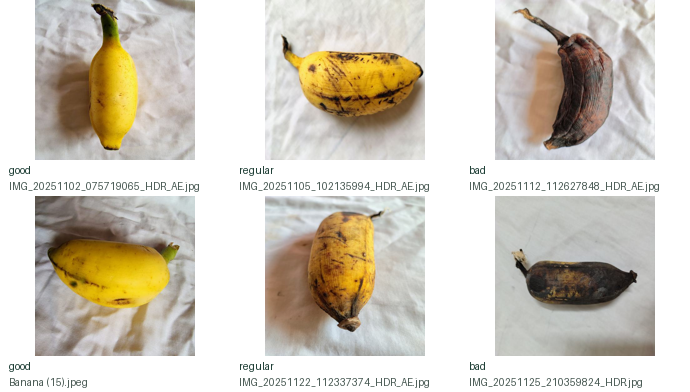

In [4]:
examples = {
    "good": ["IMG_20251102_075719065_HDR_AE.jpg", "Banana (15).jpeg"],
    "regular": ["IMG_20251105_102135994_HDR_AE.jpg", "IMG_20251122_112337374_HDR_AE.jpg"],
    "bad": ["IMG_20251112_112627848_HDR_AE.jpg", "IMG_20251125_210359824_HDR.jpg"],
}
bananas = labeled.loc[
    labeled["source"].eq("agrifreshnet") & labeled["product"].eq("banana")
].assign(basename=lambda frame: frame["filename"].map(lambda name: Path(name).name))

width, height = 230, 196
grid = Image.new("RGB", (3 * width, 2 * height), "white")
draw = ImageDraw.Draw(grid)
for column, (quality, filenames) in enumerate(examples.items()):
    for row_number, filename in enumerate(filenames):
        match = bananas.loc[
            bananas["quality"].eq(quality) & bananas["basename"].eq(filename)
        ].squeeze()
        with Image.open(config.ROOT / match["filename"]) as original:
            photo = ImageOps.exif_transpose(original).convert("RGB")
            photo.thumbnail((width - 18, height - 36))
            x = column * width + (width - photo.width) // 2
            y = row_number * height
            grid.paste(photo, (x, y))
        draw.text((column * width + 9, y + height - 32), quality, fill="#17382f")
        draw.text((column * width + 9, y + height - 16), filename, fill="#465751")

display(grid)